In [4]:
import pyranges as pr
import os
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix, csr_matrix, coo_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random

import networkx as nx

import community as community_louvain

from icecream import ic

from collections import OrderedDict

import matplotlib.pyplot as plt
%matplotlib inline
import umap.umap_ as umap
reducer = umap.UMAP()

import sklearn.decomposition as skd

import traceback
import timeit
import cProfile

In [5]:
# ROOT_PATH = '/Users/joachimwolff/data/epigenetic_graph_analyzer/'
ROOT_PATH = '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer'
# ROOT_PATH = '/home/joachim/data/MHH/epigenetic_graph_analyzer/'

path_interactions_CD34_rep1 = os.path.join(ROOT_PATH, "CD34_chicago_R1/data/CD34_chicago_R1_all_washU_text.txt")
path_interactions_CD34_rep2 = os.path.join(ROOT_PATH, "CD34_chicago_R2/data/CD34_chicago_R2_all_washU_text.txt")

path_interactions_GM12878_rep1 = os.path.join(ROOT_PATH, "GM12878_Chicago_R1/data/GM12878_Chicago_R1_all_washU_text.txt")
path_interactions_GM12878_rep2 = os.path.join(ROOT_PATH, "GM12878_Chicago_R2/data/GM12878_Chicago_R2_all_washU_text.txt")
path_interactions_GM12878_rep3 = os.path.join(ROOT_PATH, "GM12878_Chicago_R3/data/GM12878_Chicago_R3_all_washU_text.txt")

path_output_bedpe_CD34_rep1 = os.path.join(ROOT_PATH, "CD34_chicago_R1/data/CD34_chicago_R1_washU_all_text.bedpe")
path_output_bedpe_CD34_rep2 = os.path.join(ROOT_PATH, "CD34_chicago_R2/data/CD34_chicago_R2_washU_all_text.bedpe")

path_output_bedpe_GM12878_rep1 = os.path.join(ROOT_PATH, "GM12878_Chicago_R1/data/GM12878_Chicago_R1_all_washU_text.bedpe")
path_output_bedpe_GM12878_rep2 = os.path.join(ROOT_PATH, "GM12878_Chicago_R2/data/GM12878_Chicago_R2_all_washU_text.bedpe")
path_output_bedpe_GM12878_rep3 = os.path.join(ROOT_PATH, "GM12878_Chicago_R3/data/GM12878_Chicago_R3_all_washU_text.bedpe")

# path_output_cool_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.cool"
# path_output_cool_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.cool"

# path_output_cool_merged = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_merged.cool"


path_hg19_chromosome_size = os.path.join(ROOT_PATH, "hg19.chrom.sizes.sort")
# path_promoter = ROOT_PATH + "mm10_promoter.bed"
path_promoter = os.path.join(ROOT_PATH, "promoters_mifsud_unique.tab")



# # histones
# path_histones_H3K3me2_E12_5_rep1 = ROOT_PATH + "histones/GSM6505186_H3K4me2_Pinna_E12.5_WT_rep1.scaled_0100.bw"
# path_histones_H3K3me2_E12_5_rep2 = ROOT_PATH + "histones/GSM6505187_H3K4me2_Pinna_E12.5_WT_rep2.scaled_0100.bw"

# path_histones_H3K3me2_E14_5_rep1 = ROOT_PATH + "histones/GSM6505192_H3K4me2_Pinna_E14.5_WT_rep1.scaled_0100.bw"
# path_histones_H3K3me2_E14_5_rep2 = ROOT_PATH + "histones/GSM6505193_H3K4me2_Pinna_E14.5_WT_rep2.scaled_0100.bw"

# path_histones_H3K27me3_E12_5_rep1  = ROOT_PATH + "histones/GSM6505188_H3K27me3_Pinna_E12.5_WT_rep1.scaled_0100.bw"
# path_histones_H3K27me3_E12_5_rep2  = ROOT_PATH + "histones/GSM6505189_H3K27me3_Pinna_E12.5_WT_rep2.scaled_0100.bw"

# path_histones_H3K27me3_E14_5_rep1  = ROOT_PATH + "histones/GSM6505194_H3K27me3_Pinna_E14.5_WT_rep1.scaled_0100.bw"
# path_histones_H3K27me3_E14_5_rep2  = ROOT_PATH + "histones/GSM6505195_H3K27me3_Pinna_E14.5_WT_rep2.scaled_0100.bw"

# path_histones_H3K27ac_E12_5_rep1  = ROOT_PATH + "histones/GSM6505184_H3K27ac_Pinna_E12.5_WT_rep1.scaled_0100.bw"
# path_histones_H3K27ac_E12_5_rep2  = ROOT_PATH + "histones/GSM6505185_H3K27ac_Pinna_E12.5_WT_rep2.scaled_0100.bw"

# path_histones_H3K27ac_E14_5_rep1  = ROOT_PATH + "histones/GSM6505190_H3K27ac_Pinna_E14.5_WT_rep1.scaled_0100.bw"
# path_histones_H3K27ac_E14_5_rep2  = ROOT_PATH + "histones/GSM6505191_H3K27ac_Pinna_E14.5_WT_rep2.scaled_0100.bw"


# # RNA
# path_RNA_E12_5_rep1 = ROOT_PATH + "RNA/GSM6505221_RNAseq_E12.5-Pinna_TruSeq_1_cpm_100.bw"
# path_RNA_E12_5_rep2 = ROOT_PATH + "RNA/GSM6505222_RNAseq_E12.5-Pinna_TruSeq_2_cpm_100.bw"
# path_RNA_E12_5_rep3 = ROOT_PATH + "RNA/GSM6505223_RNAseq_E12.5-Pinna_TruSeq_3_cpm_100.bw"

# path_RNA_E14_5_rep1 = ROOT_PATH + "RNA/GSM6505224_RNAseq_E14.5-Pinna_TruSeq_1_cpm_100.bw"
# path_RNA_E14_5_rep2 = ROOT_PATH + "RNA/GSM6505225_RNAseq_E14.5-Pinna_TruSeq_2_cpm_100.bw"
# path_RNA_E14_5_rep3 = ROOT_PATH + "RNA/GSM6505226_RNAseq_E14.5-Pinna_TruSeq_3_cpm_100.bw"

# # ATAC
# path_ATAC_E12_5_rep1 = ROOT_PATH + "ATAC/GSM6505176_ATAC_WT_E12.5_Pinna_SK_1.scaled_0100.bw"
# path_ATAC_E12_5_rep2 = ROOT_PATH + "ATAC/GSM6505177_ATAC_WT_E12.5_Pinna_SK_2.scaled_0100.bw"
# path_ATAC_E12_5_rep3 = ROOT_PATH + "ATAC/GSM6505178_ATAC_WT_E12.5_Pinna_SK_3.scaled_0100.bw"

# path_ATAC_E14_5_rep1 = ROOT_PATH + "ATAC/GSM6505179_ATAC_E14.5_WT_Pinna_SK_1.scaled_0100.bw"
# path_ATAC_E14_5_rep2 = ROOT_PATH + "ATAC/GSM6505180_ATAC_E14.5_WT_Pinna_SK_2.scaled_0100.bw"
# path_ATAC_E14_5_rep3 = ROOT_PATH + "ATAC/GSM6505181_ATAC_E14.5_WT_Pinna_SK_3.scaled_0100.bw"



In [3]:
def washU_to_bedpe(path_input, path_output, compression='gzip'):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression=compression)
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [48]:
washU_to_bedpe(path_interactions_CD34_rep1, path_output_bedpe_CD34_rep1, compression=None)
washU_to_bedpe(path_interactions_CD34_rep2, path_output_bedpe_CD34_rep2, compression=None)
washU_to_bedpe(path_interactions_GM12878_rep1, path_output_bedpe_GM12878_rep1, compression=None)
washU_to_bedpe(path_interactions_GM12878_rep2, path_output_bedpe_GM12878_rep2, compression=None)
washU_to_bedpe(path_interactions_GM12878_rep3, path_output_bedpe_GM12878_rep3, compression=None)


In [4]:
def createMatrix(pd_interactions, cut_intervals, allow_inter_chr_interactions):
    hic_matrix_csr = dok_matrix((len(cut_intervals), len(cut_intervals)))
    ic("Matrix shape: ", hic_matrix_csr.shape)
    hic_matrix = hm.hiCMatrix()
    # try:
    hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
    # except Exception as exp:
    #     ic(exp, cut_intervals, len(cut_intervals))

    
    for row in pd_interactions.iterrows():
        
        chromosome_1 = str(row[1][0])
        start_1 = int(row[1][1]) + 1
        end_1 = int(row[1][2]) - 1

        chromosome_2 = str(row[1][3])
        start_2 = int(row[1][4]) + 1
        end_2 = int(row[1][5]) - 1

        value = float(row[1][6])
        if value == 0:
            continue
        if not allow_inter_chr_interactions:
            if chromosome_1 != chromosome_2:
                continue
        
        try:
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
            hic_matrix.matrix[bin_id_1, bin_id_2] = value

        except Exception as exp:
            print(traceback.print_exc())
            ic(chromosome_1, start_1, end_1, value)
            ic(chromosome_2, start_2, end_2, value)
            break
            # continue
        
        
    hic_matrix.matrix = hic_matrix.matrix.tocsr()
    return hic_matrix

In [49]:
def createMatrixTime2(pd_interactions, cut_intervals, allow_inter_chr_interactions):
    hic_matrix_csr = sp.lil_matrix((len(cut_intervals), len(cut_intervals)))
    ic("Matrix shape: ", hic_matrix_csr.shape)
    hic_matrix = hm.hiCMatrix()
    # try:
    hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
    # except Exception as exp:
    #     ic(exp, cut_intervals, len(cut_intervals))

    
    # for row in pd_interactions
        
    for chromosome_1, start_1, end_1, chromosome_2, start_2, end_2, value in zip(pd_interactions[0], pd_interactions[1], pd_interactions[2], pd_interactions[3], pd_interactions[4], pd_interactions[5], pd_interactions[6]):
        # chromosome_1, start_1, end_1, chromosome_2, start_2, end_2, value = interaction
        value = float(value)
        if value == 0:
            continue
        chromosome_1 = str(chromosome_1)
        chromosome_2 = str(chromosome_2)
        if not allow_inter_chr_interactions:
            if chromosome_1 != chromosome_2:
                continue
        start_1 = int(start_1) + 1
        end_1 = int(end_1) - 1
        start_2 = int(start_2) + 1
        end_2 = int(end_2) - 1
        
        try:
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
            hic_matrix.matrix[bin_id_1, bin_id_2] = value

        except Exception as exp:
            print(traceback.print_exc())
            ic(chromosome_1, start_1, end_1, value)
            ic(chromosome_2, start_2, end_2, value)
            break
            # continue
        
        
    hic_matrix.matrix = hic_matrix.matrix.tocsr()
    return hic_matrix

In [94]:
import multiprocessing
from functools import partial
from multiprocessing import Process, Queue
import time
    # except Exception as exp:
    #     ic(exp, cut_intervals, len(cut_intervals))
    


def process_interactions(interactions, hic_matrix, allow_inter_chr_interactions, pQueue):
    # row_indices = []
    # col_indices = []
    # data = []
    hic_lil_matrix = sp.lil_matrix(hic_matrix.matrix.shape)
    for chromosome_1, start_1, end_1, chromosome_2, start_2, end_2, value in zip(interactions[0], interactions[1], interactions[2], interactions[3], interactions[4], interactions[5], interactions[6]):
        # chromosome_1, start_1, end_1, chromosome_2, start_2, end_2, value = interaction
        if value == 0:
            continue
        if not allow_inter_chr_interactions:
            if chromosome_1 != chromosome_2:
                continue
        start_1 = start_1 + 1
        end_1 = end_1 - 1
        start_2 = start_2 + 1
        end_2 = end_2 - 1
        try:
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
            hic_lil_matrix[bin_id_1, bin_id_2] = value
            # row_indices.append(bin_id_1[0])
            # col_indices.append(bin_id_2[0])
            # data.append(value)
        except Exception as exp:
            print(traceback.print_exc())
            ic(chromosome_1, start_1, end_1, value)
            ic(chromosome_2, start_2, end_2, value)
            pQueue.put('Fail: ' + str(exp) + traceback.format_exc())
            return
    
    # dimensions = hic_matrix.matrix.shape[0]
    # coo = coo_matrix((data, (row_indices, col_indices)), shape=hic_matrix.matrix.shape)
    
    ic("matrix data inner thread: ", hic_lil_matrix)

    # if len(hic_lil_matrix.data) > 0:
    #     hic_csr = hic_lil_matrix.tocsr()
    # else:
    #     hic_csr = csr_matrix(hic_matrix.matrix.shape)
    pQueue.put(hic_lil_matrix)
    return

def run_parallel(interactions, hic_matrix, allow_inter_chr_interactions):
    num_processes = 8# multiprocessing.cpu_count()
    # pool = multiprocessing.Pool(processes=num_processes)
    chunk_size = len(interactions) // num_processes
    ic("Chunk size: ", chunk_size)
    ic("Number of processes: ", num_processes)
    queue = [None] * num_processes
    process = [None] * num_processes
    all_data_collected = False
    thread_done = [False] * num_processes
    interactions_thread = [None] * num_processes

    for i in range(num_processes):

        if i < num_processes - 1:
            interactions_thread[i] =  interactions.iloc[(i * chunk_size) : ((i + 1) * chunk_size)]
           
        else:
            interactions_thread[i] = interactions.iloc[(i * chunk_size):]
           

        queue[i] = Queue()
        process[i] = Process(target=process_interactions, kwargs=dict(
            interactions=interactions_thread[i],
            hic_matrix=hic_matrix,
            allow_inter_chr_interactions=allow_inter_chr_interactions,
            pQueue=queue[i]
        )
        )

        process[i].start()

    fail_flag = False
    fail_message = ''
    while not all_data_collected:
        for i in range(num_processes):
            if queue[i] is not None and not queue[i].empty():
                queue_data = queue[i].get()
                if (type(queue_data) == str) and ('Fail' in queue_data):
                    fail_flag = True
                    fail_message = queue_data
                else:
                    hic_matrix.matrix += queue_data

                queue[i] = None
                process[i].join()
                process[i].terminate()
                process[i] = None
                thread_done[i] = True
                interactions_thread[i] = None
        all_data_collected = True
        for thread in thread_done:
            if not thread:
                all_data_collected = False
        time.sleep(1)

    if fail_flag:
        return fail_message, None
    
    hic_matrix.matrix = hic_matrix.matrix.tocsr()
    return hic_matrix

def createMatrixTime(pd_interactions, cut_intervals, allow_inter_chr_interactions):
    hic_matrix_csr = sp.lil_matrix((len(cut_intervals), len(cut_intervals)))
    ic("Matrix shape: ", hic_matrix_csr.shape)
    hic_matrix = hm.hiCMatrix()
    # try:
    hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
    # Modify the code to pass the interactions to the run_parallel function
    # interactions = zip(pd_interactions[0], pd_interactions[1], pd_interactions[2], pd_interactions[3], pd_interactions[4], pd_interactions[5], pd_interactions[6])
    # interactions = list(interactions)
    hic_matrix = run_parallel(pd_interactions, hic_matrix, allow_inter_chr_interactions)

    return hic_matrix

In [9]:
def createCutIntervals(chromosome_size_file, resolution):
    chrom_sizes = OrderedDict()
    size_genome = 0
    with open(chromosome_size_file, 'r') as file:
        file_ = True
        while file_:
            file_ = file.readline().strip()
            if file_ != '':
                line_split = file_.split('\t')
                chrom_sizes[line_split[0]] = int(line_split[1])
                size_genome += int(line_split[1])
    # chrom_sizes = list(chrom_sizes.items())

    cut_intervals = []
    if isinstance(resolution, int):
        for chromosome in chrom_sizes:
            for interval in range(0, chromosome[1], resolution):
                cut_intervals.append(tuple([chromosome[0], interval,
                                            min(chromosome[1], interval + resolution), 1.0]))
    else:
        restriction_cut_sites = pd.read_table(resolution, sep='\t')
        # ic(restriction_cut_sites)
        # restriction_cut_sites.columns = ['Chromosome', 'Start', 'End', '.', 'x', 'Strand']
        for row in restriction_cut_sites.iterrows():
            # ic(row, row[1])
            
            if row[1]['Chromosome'] in chrom_sizes:
                if int(row[1]['Start']) != int(row[1]['End']):
                    cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))
    
    return cut_intervals

In [78]:

def importInteractionsFromWashUTime(list_of_washU_files, cut_intervals, allow_inter_chr_interactions=False, compression='gzip'):
    
    hic_matrix_list = []
    pd_interactions_list = []
    matrix_merged_csr = None

    
                
    # print(cut_intervals)
    for i, path_interactions in enumerate(list_of_washU_files):
        dtype_dict = {0:str, 1:int, 2:int, 3:str, 4:int, 5:int, 6:float}
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression=compression, dtype=dtype_dict)
        
        # pr_interactions_list.append(pd_interactions)
        ic("COmpute matrix")

        hic_matrix = createMatrixTime(pd_interactions, cut_intervals, allow_inter_chr_interactions)
        
        
        hic_matrix_list.append(hic_matrix)
        ic("Merge matrix")

        # merge matrices
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
    
    
    ic("COmpute intersection matrix")
    # compute an intersection matrix
    intersection_result_matrix = hic_matrix_list[0].matrix
            
    if len(hic_matrix_list) > 1:
        for hic_matrix in hic_matrix_list[1:]:
            intersection_matrix = intersection_result_matrix.multiply(hic_matrix.matrix).tocsr()
            intersection_matrix.eliminate_zeros()
            non_zero_ids = intersection_matrix.nonzero()
            data_merged_matrix = np.asarray(intersection_result_matrix[non_zero_ids]).flatten()
            data_hic_matrix = np.asarray(hic_matrix.matrix[non_zero_ids]).flatten()
            data_intersection = data_merged_matrix + data_hic_matrix
            intersection_result_matrix = csr_matrix((data_intersection, non_zero_ids),shape=intersection_result_matrix.shape)

    hic_matrix_list.append(matrix_merged_csr)
    hic_matrix_list.append(intersection_result_matrix / len(list_of_washU_files))

    return hic_matrix_list

In [28]:
pd_interactions = pd.read_table(path_interactions_GM12878_rep1, header=None, sep='\t|,', compression=None)


In [31]:
pd_interactions
dtype_dict = {0:str, 1:int, 2:int, 3:str, 4:int, 5:int, 6:float}

,0,1,2,3,4,5,6
0,chr1,848169,850618,chr1,540723,542529,1.33
1,chr1,848169,850618,chr1,634957,636805,1.25
2,chr1,848169,850618,chr1,761174,772747,0.77
3,chr1,848169,850618,chr1,772748,773890,0.74
4,chr1,848169,850618,chr1,773891,774507,0.75
...,...,...,...,...,...,...,...
2655513,chrX,154896386,154900044,chrX,154907720,154911165,0.91
2655514,chrX,154896386,154900044,chrX,154911181,154911740,0.54
2655515,chrX,154896386,154900044,chrX,154911741,154924544,1.16
2655516,chrX,154896386,154900044,chrX,154924545,154929359,1.12


In [10]:
cut_intervals = createCutIntervals(path_hg19_chromosome_size, resolution=os.path.join(ROOT_PATH,  'Digest_Human_hg19_HindIII_header.txt'))

In [38]:
matrix_time = importInteractionsFromWashUTime([path_interactions_GM12878_rep1], cut_intervals, compression=None)


ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)


In [50]:
matrix_time2 = importInteractionsFromWashUTime([path_interactions_GM12878_rep1], cut_intervals, compression=None)


ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)


In [51]:
matrix_time2[0].matrix

<837646x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 2568945 stored elements in Compressed Sparse Row format>

In [95]:
matrix_time_parallel = importInteractionsFromWashUTime([path_interactions_GM12878_rep1], cut_intervals, compression=None)


ic| 'COmpute matrix'
ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)
ic| 'Chunk size: ', chunk_size: 331939
ic| 'Number of processes: ', num_processes: 8
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 320252 stored elements in List of Lists format>
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 320524 stored elements in List of Lists format>
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 320739 stored elements in List of Lists format>
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 3

In [ ]:
matrix_time_parallel

In [16]:
matrix_non_parallel = importInteractionsFromWashU([path_interactions_GM12878_rep1], path_hg19_chromosome_size, resolution=os.path.join(ROOT_PATH,  'Digest_Human_hg19_HindIII_header.txt'), compression=None)


ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)


In [57]:
matrix_non_parallel[0].matrix

<837646x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 2568945 stored elements in Compressed Sparse Row format>

In [58]:
matrix_time[0].matrix

<837646x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 2568945 stored elements in Compressed Sparse Row format>

In [37]:
matrix_time_parallel[0].matrix

<837646x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 2568944 stored elements in Compressed Sparse Row format>

In [68]:
matrix_time_parallel[0].matrix

<837646x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 2568945 stored elements in Compressed Sparse Row format>

In [5]:

def importInteractionsFromWashU(list_of_washU_files, chromosome_size_file, resolution, allow_inter_chr_interactions=False, compression='gzip'):
    
    hic_matrix_list = []
    pd_interactions_list = []
    matrix_merged_csr = None

    chrom_sizes = OrderedDict()
    size_genome = 0
    with open(chromosome_size_file, 'r') as file:
        file_ = True
        while file_:
            file_ = file.readline().strip()
            if file_ != '':
                line_split = file_.split('\t')
                chrom_sizes[line_split[0]] = int(line_split[1])
                size_genome += int(line_split[1])
    # chrom_sizes = list(chrom_sizes.items())

    cut_intervals = []
    if isinstance(resolution, int):
        for chromosome in chrom_sizes:
            for interval in range(0, chromosome[1], resolution):
                cut_intervals.append(tuple([chromosome[0], interval,
                                            min(chromosome[1], interval + resolution), 1.0]))
    else:
        restriction_cut_sites = pd.read_table(resolution, sep='\t')
        # ic(restriction_cut_sites)
        # restriction_cut_sites.columns = ['Chromosome', 'Start', 'End', '.', 'x', 'Strand']
        for row in restriction_cut_sites.iterrows():
            # ic(row, row[1])
            
            if row[1]['Chromosome'] in chrom_sizes:
                if int(row[1]['Start']) != int(row[1]['End']):
                    cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))
                
    # print(cut_intervals)
    for i, path_interactions in enumerate(list_of_washU_files):
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression=compression)
        
        # pr_interactions_list.append(pd_interactions)
        hic_matrix = createMatrix(pd_interactions, cut_intervals, allow_inter_chr_interactions)
        
        
        hic_matrix_list.append(hic_matrix)

        # merge matrices
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
    
    

    # compute an intersection matrix
    intersection_result_matrix = hic_matrix_list[0].matrix
            
    if len(hic_matrix_list) > 1:
        for hic_matrix in hic_matrix_list[1:]:
            intersection_matrix = intersection_result_matrix.multiply(hic_matrix.matrix).tocsr()
            intersection_matrix.eliminate_zeros()
            non_zero_ids = intersection_matrix.nonzero()
            data_merged_matrix = np.asarray(intersection_result_matrix[non_zero_ids]).flatten()
            data_hic_matrix = np.asarray(hic_matrix.matrix[non_zero_ids]).flatten()
            data_intersection = data_merged_matrix + data_hic_matrix
            intersection_result_matrix = csr_matrix((data_intersection, non_zero_ids),shape=intersection_result_matrix.shape)

    hic_matrix_list.append(matrix_merged_csr)
    hic_matrix_list.append(intersection_result_matrix / len(list_of_washU_files))

    return hic_matrix_list

In [8]:
# chr6	52164817	52164877	Hoxa2_1

In [69]:
# interaction_matrices_sample_CD34 = importInteractionsFromWashU([path_interactions_CD34_rep1], path_hg19_chromosome_size, resolution=os.path.join(ROOT_PATH,  'Digest_Human_hg19_HindIII_header.txt'), compression=None)
interaction_matrices_sample_CD34_parallel = importInteractionsFromWashUTime([path_interactions_CD34_rep1, path_interactions_CD34_rep2], cut_intervals, compression=None)

interaction_matrices_sample_GM12878_parallel = importInteractionsFromWashUTime([path_interactions_GM12878_rep2, path_interactions_GM12878_rep3], cut_intervals, compression=None)
# path_interactions_GM12878_rep1, 

ic| 'COmpute matrix'
ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)
ic| 'Chunk size: ', chunk_size: 390743
ic| 'Number of processes: ', num_processes: 8
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 380530 stored elements in List of Lists format>
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 381281 stored elements in List of Lists format>
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 381391 stored elements in List of Lists format>
ic| "matrix data inner thread: ": 'matrix data inner thread: '
    hic_lil_matrix: <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
                    	with 3

In [60]:
# interaction_matrices_sample_CD34 = importInteractionsFromWashU([path_interactions_CD34_rep1], path_hg19_chromosome_size, resolution=os.path.join(ROOT_PATH,  'Digest_Human_hg19_HindIII_header.txt'), compression=None)
interaction_matrices_sample_CD34 = importInteractionsFromWashUTime([path_interactions_CD34_rep1, path_interactions_CD34_rep2], cut_intervals, compression=None)

interaction_matrices_sample_GM12878 = importInteractionsFromWashUTime([path_interactions_GM12878_rep2, path_interactions_GM12878_rep3], cut_intervals, compression=None)
# path_interactions_GM12878_rep1, 

ic| 'COmpute matrix'
ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)
ic| 'Merge matrix'
ic| 'COmpute matrix'
ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)
ic| 'Merge matrix'
ic| 'COmpute intersection matrix'
ic| 'COmpute matrix'
ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)
ic| 'Merge matrix'
ic| 'COmpute matrix'
ic| 'Matrix shape: ', hic_matrix_csr.shape: (837646, 837646)
ic| 'Merge matrix'
ic| 'COmpute intersection matrix'


 <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
 	with 5617494 stored elements in Compressed Sparse Row format>,
 <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
 	with 1989020 stored elements in Compressed Sparse Row format>]

 <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
 	with 5617494 stored elements in Compressed Sparse Row format>,
 <837646x837646 sparse matrix of type '<class 'numpy.float64'>'
 	with 1989020 stored elements in Compressed Sparse Row format>]

In [94]:
pd.read_csv(path_promoter, sep='\t', header=None)

,0,1,2,3
0,Name,Chromosome,Start,End
1,PALMD-001,chr1,100105297,100123456
2,"LZIC-001,LZIC-005,LZIC-202,LZIC-201",chr1,10021141,9990584
3,"FRRS1-001,FRRS1-201",chr1,100231939,100238229
4,U4.31-201,chr1,100249718,100249837
...,...,...,...,...
21857,"ZFY-001,ZFY-002,ZFY-202,ZFY-201,ZFY-203",chrY,2800574,2805795
21858,"AMELY-001,AMELY-002,AMELY-201",chrY,6740033,6740152
21859,"TBL1Y-001,TBL1Y-002,TBL1Y-003,TBL1Y-201",chrY,6781549,6781668
21860,U6.1084-201,chrY,7241381,7241500


In [91]:
interaction_matrices_sample_CD34[2].data

array([0.85, 0.8 , 0.73, ..., 1.87, 1.87, 4.24])

In [148]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        
        view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1], bait_location[1])
        if view_point_start is None:
            
            view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1]+1, bait_location[1]+1)
            
            if view_point_start is None:
                print(traceback.print_exc())
                ic(bait_location, row)
                break
        matrix_list.append(chic_matrix[-1][view_point_start[0], :])
        bait_list.append([row[['Name']].str.split(',')[0][0], str(row['Chromosome']) + ":" + str(row['Start']) + "-"+ str(row['End'])])

    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    return sample_matrix, bait_list

In [149]:
sample_matrix_CD34, bait_list_CD34 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_CD34_parallel)
sample_matrix_GM12878, bait_list_GM12878 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_GM12878_parallel)

In [126]:
cut_intervals[836321][0] + ":" + str(cut_intervals[836321][1]) + "-" +  str(cut_intervals[836321][2])

'chrY:24899545-24899911'

In [116]:
sample_matrix_GM12878

<21861x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 3386005 stored elements in Compressed Sparse Row format>

In [67]:
sample_matrix_GM12878

<37608x837646 sparse matrix of type '<class 'numpy.float64'>'
	with 153 stored elements in Compressed Sparse Row format>

In [150]:
bait_list_CD34

[['PALMD-001', 'chr1:100105297-100123456'],
 ['LZIC-001', 'chr1:10021141-9990584'],
 ['FRRS1-001', 'chr1:100231939-100238229'],
 ['U4.31-201', 'chr1:100249718-100249837'],
 ['AL451051.1-201', 'chr1:100294309-100296677'],
 ['AGL-001', 'chr1:100313182-100317771'],
 ['SLC35A3-001', 'chr1:100431060-100431179'],
 ['U6.754-201', 'chr1:100447328-100447447'],
 ['U6.354-201', 'chr1:100472331-100472450'],
 ['HIAT1-001', 'chr1:100502426-100508969'],
 ['RNF223-201', 'chr1:1005268-1005387'],
 ['SASS6-001', 'chr1:100597163-100598665'],
 ['CCDC76-003', 'chr1:100598667-100607640'],
 ['LRRC39-001', 'chr1:100634353-100634472'],
 ['DBT-001', 'chr1:100713721-100713840'],
 ['RP11-305E17.6-001', 'chr1:100737743-100737862'],
 ['MIR553-201', 'chr1:100738162-100748133'],
 ['CDC14A-004', 'chr1:100811790-100811909'],
 ['AC104457.1-201', 'chr1:100844995-100845114'],
 ['UBE4B-002', 'chr1:10094083-10094202'],
 ['RP5-837M10.4-001', 'chr1:100951242-100958750'],
 ['GPR88-001', 'chr1:101000598-101008738'],
 ['VCAM1-004

In [110]:
bait_list_CD34_df = pd.DataFrame(bait_list_CD34, columns=['Name'])
bait_list_CD34_df[bait_list_CD34_df["Name"].str.contains("PDE1C")]


,Name
9011,PDE1C-001


In [157]:
bait_list_GM12878_df = pd.DataFrame(bait_list_GM12878, columns=['Name', "Position"])
bait_list_GM12878_df[bait_list_GM12878_df["Name"].str.contains("HOXA")]

,Name,Position
8958,HOXA2-001,chr7:27137355-27143253
8961,HOXA5-001,chr7:27181847-27195103
8962,HOXA7-001,chr7:27196610-27201143
8965,HOXA11-AS1-007,chr7:27221403-27230231
8967,HOXA13-001,chr7:27238414-27242311


In [112]:
promoters = pr.read_bed(path_promoter)

In [111]:
promoters.df[promoters.df['Name'] == 'CBX3-001,CBX3-002,CBX3-004,CBX3-003']

,Chromosome,Start,End,Name
8949,chr7,26238187,26246386,"CBX3-001,CBX3-002,CBX3-004,CBX3-003"


In [399]:
def createGraphAndFindCommunities(sample_matrix, bait_list, path_output_graphml, cut_intervals, RNA_counts, threshold=5.0):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    # threshold_elements_list = []
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if sample_matrix.data[i] < threshold:
            # threshold_elements_list.append(bait)
            continue
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"
            G.nodes[OE + number_of_samples]['position'] = cut_intervals[OE][0] + ":" + str(cut_intervals[OE][1]) + "-" +  str(cut_intervals[OE][2])

    print("bait in bait_ids")
    for bait in bait_ids:
        # if bait in threshold_elements_list:
        #     continue
        if bait in G.nodes:
            G.nodes[bait]['name'] = bait_list[bait][0]
            G.nodes[bait]['colorType'] = "green"
            G.nodes[bait]['position'] = bait_list[bait][1]
            try:
                data = gm12878_rna_dictionary[bait_list[bait][0].split('-')[0]]
            
                G.nodes[bait]['RNA count'] = data[3]
            except Exception as exp:
                continue


    # remove = [node for node,degree in dict(G.degree()).items() if degree == 1 or degree == 0]
    # G.remove_nodes_from(remove)


    # remove = [node for node,degree in dict(G.degree()).items() if degree == 0]
    # G.remove_nodes_from(remove)


    print("partiion creating")

    # partition = community_louvain.best_partition(G)
    partition_list = nx.community.louvain_communities(G, seed=42)

    print("enumerate partion creating")

    for partition_id, partition in enumerate(partition_list):
        for node in partition:
            G.nodes[node]['partition'] = partition_id
            G.nodes[node]['partition_color'] = partition_id


    print("write graphml")

    nx.write_graphml(G, path_output_graphml)

    return G, partition_list

In [400]:
G_Pinna_CD34, partition_CD34 = createGraphAndFindCommunities(sample_matrix_CD34, bait_list_CD34, os.path.join(ROOT_PATH, "CD34.graphml"), cut_intervals=cut_intervals, RNA_counts=gm12878_rna_dictionary, threshold=5.0)
G_Pinna_GM12878, partition_GM12878 = createGraphAndFindCommunities(sample_matrix_GM12878, bait_list_GM12878, os.path.join(ROOT_PATH, "GM12878.graphml"), cut_intervals=cut_intervals, RNA_counts=gm12878_rna_dictionary, threshold=5.0)

bait in bait_ids
partiion creating
enumerate partion creating
write graphml
bait in bait_ids
partiion creating
enumerate partion creating
write graphml


In [159]:
# write out clusters, with their ids, the bait name and the OE. all with their chromosomal location
#
# Are the genes of a cluster similar regulated?
# - RNA of genes similar high? compare tpm
# - 

{'name': 'HOXA2-001',
 'colorType': 'green',
 'position': 'chr7:27137355-27143253',
 'partition': 300,
 'partition_color': 300}

In [397]:
gm12878_rna_dictionary = gm12878_rna_counts.set_index(0)[1:].to_dict(orient='index')
# gm12878_rna_counts

In [396]:
dictionary['A1CF'][3]

12.0

In [166]:
import pyBigWig

In [199]:
import pyBigWig
import numpy as np

path_rna_gm12878_R1 = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/GM12878_RNA/GSM758559_wgEncodeCshlLongRnaSeqGm12878CellPapMinusRawSigRep1.bigWig"
path_rna_gm12878_R2 = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/GM12878_RNA/GSM758559_wgEncodeCshlLongRnaSeqGm12878CellPapMinusRawSigRep2.bigWig"

# Open the bigWig file
bw = pyBigWig.open()

# Specify the genomic location
chromosome = 'chr1'
start = 100231939
end = 100238229

# Retrieve the data from the specific location
# Assuming you have a NumPy array called 'data'
data = bw.values(chromosome, start, end, numpy=True)

# Create a boolean mask to identify NaN values
mask = np.isnan(data)

# Filter out the NaN values
filtered_data = data[~mask]

# Print the filtered data
print(filtered_data.mean())
print(filtered_data.max())



RuntimeError: Received an error during file opening!

In [191]:
promoters

,Chromosome,Start,End,Name
0,chr1,100105297,100123456,PALMD-001
1,chr1,10021141,9990584,"LZIC-001,LZIC-005,LZIC-202,LZIC-201"
2,chr1,100231939,100238229,"FRRS1-001,FRRS1-201"
3,chr1,100249718,100249837,U4.31-201
4,chr1,100294309,100296677,AL451051.1-201
...,...,...,...,...
21856,chrY,2800574,2805795,"ZFY-001,ZFY-002,ZFY-202,ZFY-201,ZFY-203"
21857,chrY,6740033,6740152,"AMELY-001,AMELY-002,AMELY-201"
21858,chrY,6781549,6781668,"TBL1Y-001,TBL1Y-002,TBL1Y-003,TBL1Y-201"
21859,chrY,7241381,7241500,U6.1084-201


In [195]:
# promoters["Name"].contains('FRRS1-001')

promoters.df[promoters.df["Name"].str.contains("FRRS1-001")]

,Chromosome,Start,End,Name
2,chr1,100231939,100238229,"FRRS1-001,FRRS1-201"


In [303]:
gm12878_rna_counts = pd.read_table(os.path.join(ROOT_PATH, "GM12878_RNA/GM12878_counts.tabular"), sep='\t', header=None)

In [379]:
def computeRNAsimilarity(partition_sample, bait_list, graph, RNA_counts):
    
    mean_values = []
    max_values = []
    min_values = []
    var_values = []
    partition_ids = []
    for i, partition in enumerate(partition_sample):
        partition_list = []
        for node in partition:
            if node < len(bait_list):
                # print(graph.nodes[node]['position'], graph.nodes[node]['name'])
                data = RNA_counts[RNA_counts[0] == graph.nodes[node]['name'].split('-')[0]]
                if (len(data) == 0):
                    continue
                partition_list.append(data.values[0][3])

        if len(partition_list) >= 2:
            mean_values.append(np.mean(partition_list))
            max_values.append(np.max(partition_list))
            min_values.append(np.min(partition_list))
            var_values.append(np.var(partition_list))

            partition_ids.append(i)
    mean_values = np.array(mean_values)
    max_values = np.array(max_values)
    min_values = np.array(min_values)
    var_values = np.array(var_values)
    partition_ids = np.array(partition_ids)

    return mean_values, max_values, min_values, var_values, partition_ids

In [380]:
mean_values, max_values, min_values, var_values, partition_ids = computeRNAsimilarity(partition_GM12878, bait_list_GM12878, G_Pinna_GM12878, gm12878_rna_counts)



In [344]:
partition_ids = np.arange(len(partition_GM12878))
mask = mean_values == np.float32(0)
partition_ids = partition_ids[~mask]
mean_values = mean_values[~mask]
max_values = max_values[~mask]
min_values = min_values[~mask]
mean_max = mean_max[~mask]
mean_min = mean_min[~mask]



IndexError: boolean index did not match indexed array along dimension 0; dimension is 3369 but corresponding boolean dimension is 556

In [352]:
mask = mean_values == np.float32(0)

In [355]:
len(mean_values
    )

556

In [317]:
# gm12878_rna_counts[3] = np.mean(gm12878_rna_counts[1] + gm12878_rna_counts[2])
gm12878_rna_counts[1] = gm12878_rna_counts[1].astype(int)
gm12878_rna_counts[2] = gm12878_rna_counts[2].astype(int)
gm12878_rna_counts[3] = gm12878_rna_counts[1] + gm12878_rna_counts[2]
gm12878_rna_counts[3] = gm12878_rna_counts[3] / 2

In [310]:
gm12878_rna_counts.dtypes

0     object
1      int64
2      int64
3    float64
dtype: object

In [318]:
gm12878_rna_counts

,0,1,2,3
0,A1BG,68,16,42.0
1,A1BG-AS1,48,20,34.0
2,A1CF,10,14,12.0
3,A2M,17,9,13.0
4,A2M-AS1,10,10,10.0
...,...,...,...,...
28260,ZYG11A,1456,1168,1312.0
28261,ZYG11B,2589,2620,2604.5
28262,ZYX,297,86,191.5
28263,ZZEF1,5384,2464,3924.0


In [376]:
gm12878_rna_counts[gm12878_rna_counts[0] == "PALMD" ].values[0][3]

7.0

In [224]:
import numpy as np

n = len(partition_GM12878)  # replace with your desired value of n
arr = np.arange(len(partition_GM12878))

print(arr)


[   0    1    2 ... 3366 3367 3368]


In [226]:
import numpy as np

# Example arrays
array1 = np.array([3, 1, 4, 2])
array2 = np.array(['C', 'A', 'D', 'B'])

# Sort array1 and get the indices
sorted_indices = np.argsort(array1)

# Sort array1 and array2 based on the sorted indices
sorted_array1 = array1[sorted_indices]
sorted_array2 = array2[sorted_indices]

# Print the sorted arrays
print(sorted_array1)  # [1 2 3 4]
print(sorted_array2)  # ['A' 'B' 'C' 'D']


3369

In [365]:
mean_values[sorted_indices]

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.50000000e-01,
       2.50000000e-01, 2.50000000e-01, 2.50000000e-01, 5.00000000e-01,
       7.50000000e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.25000000e+00, 1.25000000e+00, 1.33333333e+00, 1.75000000e+00,
       2.16666667e+00, 2.50000000e+00, 2.66666667e+00, 2.75000000e+00,
       2.75000000e+00, 2.75000000e+00, 2.75000000e+00, 2.75000000e+00,
       2.75000000e+00, 3.00000000e+00, 3.00000000e+00, 3.16666667e+00,
       3.25000000e+00, 3.25000000e+00, 3.33333333e+00, 3.50000000e+00,
       3.75000000e+00, 3.75000000e+00, 4.40000000e+00, 4.50000000e+00,
       4.50000000e+00, 4.50000000e+00, 4.75000000e+00, 5.00000000e+00,
       5.19444444e+00, 5.50000000e+00, 5.50000000e+00, 5.50000000e+00,
       5.50000000e+00, 5.75000000e+00, 6.25000000e+00, 6.25000000e+00,
      

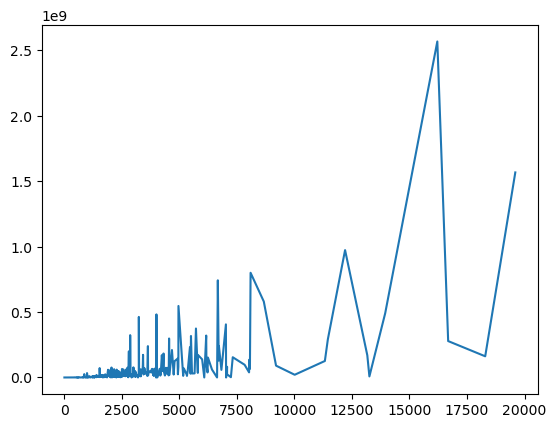

In [364]:
sorted_indices = np.argsort(mean_values)

# Sort array1 and array2 based on the sorted indices
sorted_array1 = mean_values[sorted_indices]
sorted_array2 = var_values[sorted_indices]
plt.plot(sorted_array1, sorted_array2)

In [160]:
partition_GM12878

[{0, 2237, 2239, 2245, 2246, 48130, 48469, 48883, 48914, 48959},
 {2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  20,
  21,
  23,
  24,
  25,
  26,
  49012,
  49037,
  49039,
  49040,
  49042,
  49043,
  49049,
  49054,
  49059,
  49062,
  49103,
  49117,
  49118,
  49121,
  49122,
  49127,
  49129,
  49135,
  49136,
  49153,
  49154,
  49157,
  49164,
  49165,
  49166,
  49191,
  49193,
  49210,
  49216,
  49225,
  49235,
  49236,
  49237,
  49241,
  49245,
  49247,
  49251,
  49265,
  49333,
  49362,
  49363,
  49365,
  49367,
  49375,
  49376,
  49456,
  49481,
  49484,
  49485,
  49497,
  49499,
  49500,
  49507,
  49508,
  49510,
  49515,
  49534,
  49539,
  49546,
  49547},
 {1, 28, 36, 23825, 23861},
 {44, 46, 51332},
 {45,
  47,
  48,
  49,
  50,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  78,
  79,
  81,
  82,
  84,
  85,
  86,
  89,
  

In [161]:
G_Pinna_CD34.nodes[8958]


{'name': 'HOXA2-001',
 'colorType': 'green',
 'position': 'chr7:27137355-27143253',
 'partition': 580,
 'partition_color': 580}

In [125]:
G_Pinna_GM12878.nodes[8958]


{'name': 'HOXA2-001',
 'colorType': 'green',
 'partition': 1030,
 'partition_color': 1030}

## Is the bait still in the same community between conditions?

### Compute the jaccard similarity between all communities

In [127]:
def jaccardSimiliarityCommunities(community_1, community_2, number_of_baits):
    intersection_communities_nodes = []
    intersection_communities_jaccard = np.zeros((len(community_1), len(community_2)))
    intersection_communities_bait_jaccard = np.zeros((len(community_1), len(community_2)))
    for i in range(len(community_1)):
        intersection_communities_nodes.append({})
        for j in range(len(community_2)):
            intersection = community_1[i].intersection(community_2[j])

            if len(intersection) > 0:
                intersection_communities_nodes[i][j] = intersection
                intersection_communities_jaccard[i, j] = len(intersection) / len(community_1[i].union(community_2[j]))
                bait_intersection = {x for x in intersection if x <= number_of_baits}
                bait_community_1 = {x for x in community_1[i] if x <= number_of_baits}
                bait_community_2 = {x for x in community_2[j] if x <= number_of_baits}
                intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_community_1.union(bait_community_2))

    return intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard

In [128]:
intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard = jaccardSimiliarityCommunities(partition_CD34, partition_GM12878, sample_matrix_CD34.shape[0])

In [130]:
intersection_communities_nodes[1030]

{728: {6517,
  6518,
  6519,
  6520,
  6521,
  6522,
  6523,
  6524,
  6525,
  6526,
  6527,
  624482,
  624483,
  624486,
  624501,
  624528,
  624591,
  624594,
  624616,
  624619,
  624634,
  624635,
  624640,
  624650,
  624662,
  624671}}

In [131]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values = np.sort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)


Top 10 values per row:
[[0.2        0.         0.         0.         0.        ]
 [0.04545455 0.         0.         0.         0.        ]
 [0.86956522 0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   0  766  782  781  780]
 [ 145  766  782  781  780]
 [ 145  766  782  781  780]
 ...
 [2336  766  782  781  780]
 [2336  766  782  781  780]
 [2336  766  782  781  780]]


In [132]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values_communities = np.sort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices_communities = np.argsort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)

Top 10 values per row:
[[0.2        0.         0.         0.         0.        ]
 [0.04545455 0.         0.         0.         0.        ]
 [0.86956522 0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   0  766  782  781  780]
 [ 145  766  782  781  780]
 [ 145  766  782  781  780]
 ...
 [2336  766  782  781  780]
 [2336  766  782  781  780]
 [2336  766  782  781  780]]


In [93]:
top_10_indices[1268]

array([ 235, 1055,  347,  360,  359])

In [94]:
top_10_indices_communities[12]

array([  7, 354, 348, 349, 350])

In [55]:
top_10_values_communities[1268]

array([0.41145833, 0.02281369, 0.00581395, 0.        , 0.        ])

In [111]:
top_10_values[1268]

array([1., 0., 0., 0., 0.])

In [57]:
intersection_communities_nodes[1268]

[{8146, 8147, 642455, 642467, 642579, 642580},
 {641455},
 {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8761,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  641958,
  641960,
  641961,
  642001,
  642002,
  642003,
  642013,
  642074,
  642075,
  642076,
  642077,
  642078,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642096,
  642198,
  642199,
  642309,
  642310,
  642351,
  642352,
  642353,
  642355,
  642356,
  642358,
  642359,
  642360,
  642361,
  642411,
  642413,
  642426,
  642436,
  642437,
  642549,
  642551,
  642552,
  642554,
  642555,
  642559,
  642560,
  642562,
  642602,
  642606,
  642646,
  642649,
  642650,
  642651,
  642653,
  642671,
  642672}]

After the jaccard similarity sorting:
- Which clusters have the identical baits?
- Which baits are equal between clusters?
- Which baits changed the cluster?
- Which baits are exclusive in one sample? For example jaccard similarity of Hoxa2 cluster is 0.76 to the clostest one, 0.03 to the next, and to all other 0. Where are the missing 0.2? Ideas: Baits are exclusive in sample 1 xor sample 2.

- For equal: 
  - How did the histone / RNA changed between the conditions? 
    - per both sides of the interaction get the histone / RNA / ATAC data, with replicates for DESeq2 table
  - How did the interaction strength changed? (Binary contact number change / summed value change / mean change) per community
  - Did we get new OE interactions of those same baits?

- Baits changed cluster:
  - How did the histone / RNA changed between the conditions? 
  - How did it changed at those contacts that were lost / gained? Identifiy the contacts responsible for the loss / gain within the community. Get for both ends of a gained / lost contact from both samples the Histone / RNA / ATAC data for Deseq2 table

- Exclusive in one sample:
  - How did the histone / RNA changed between the conditions at the locations of baits / OE? 
  - Which OE have a degree of 1, 2, 3, ..., n?

Can we identifiy patterns? 
- 


#### Plot the distribution of the jaccard index for baits

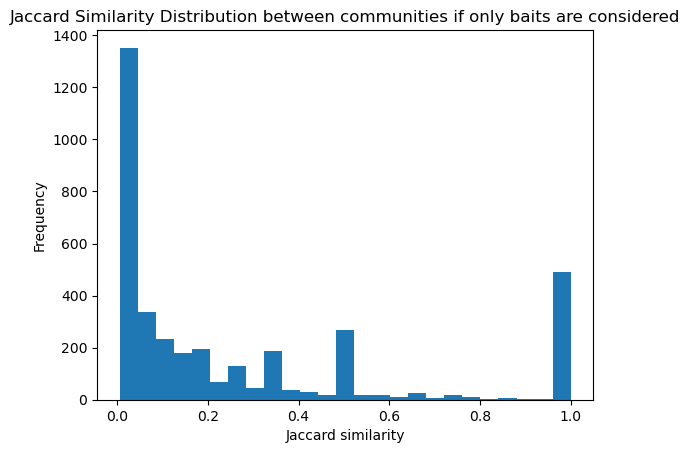

In [133]:
import numpy as np
import matplotlib.pyplot as plt

matrix = top_10_values
# Assuming your 2D matrix is named 'matrix'
non_zero_values = matrix[matrix != 0]

# Plot the histogram
plt.hist(non_zero_values, bins=25)
plt.xlabel('Jaccard similarity')
plt.ylabel('Frequency')
plt.title('Jaccard Similarity Distribution between communities if only baits are considered')
plt.show()

## Baits stay the same
- Do we see interaction strength change?

In [134]:
#### Take communities with a jaccard index of the baits of only 1.0
def findCommunitiesWithJaccardIndexOfOne(sorted_jaccard, partition_1, partition_2, number_of_baits, sample_matrices):
    
    count_table = []

    matching_indices = np.where(sorted_jaccard == 1.0)[0]
    for index in matching_indices:
        community_1 = partition_1[index]
        community_2 = partition_2[top_10_indices[index][0]]

        # get all baits
        community_1_baits = {x for x in community_1 if x <= number_of_baits}
        community_2_baits = {x for x in community_2 if x <= number_of_baits}
        baits = community_1_baits.union(community_2_baits)

        # if index == 3692:
        # ic(baits, index, community_1, community_2)

        # get for each bait from sample A and B the interactions
        for bait_index in baits:
            # matrix_sample_1[bait_index, :]
            # matrix_sample_2[bait_index, :]
            # ic(matrix_sample_1[bait_index, :], matrix_sample_2[bait_index, :])
            try:
                all_OE = np.unique(np.concatenate([intersection_matrices[bait_index, :].nonzero()[1], intersection_matrices[bait_index, :].nonzero()[1]]))
            except:
                ic(bait_index)
                ic(matrices_sample_1[0][bait_index, :])
                ic(matrices_sample_2[0][bait_index, :])
                break
            for interaction_index in all_OE:
                id = str(bait_index) + "_" + str(interaction_index)
                count_table_line = []
                count_table_line.append(id)
                for matrix in matrices_sample_1:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                for matrix in matrices_sample_2:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                count_table.append(count_table_line)
                # ic(interaction_index)
                # ic(matrix_sample_1[bait_index, interaction_index])

                # ic(matrix_sample_2[bait_index, interaction_index])
        # break
        # create a table to compare the interactions
    
    columns_ids = ['GeneID']
    for i in range(len(matrices_sample_1)):
        columns_ids.append("Sample1_" + str(i))
    for i in range(len(matrices_sample_2)):
        columns_ids.append("Sample2_" + str(i))
    count_table_df = pd.DataFrame(count_table, columns=columns_ids)
    count_table_df = count_table_df.set_index('GeneID')
    return count_table_df



In [135]:
count_table_df = findCommunitiesWithJaccardIndexOfOne(top_10_values, partition_Pinna_E12_5, partition_Pinna_E14_5, sample_matrix_Pinna_E12_5.shape[0], interaction_matrices_sample_Pinna_12_5[:2], interaction_matrices_sample_Pinna_14_5[:2])

ic| bait_index: 6


TypeError: 'hiCMatrix' object is not subscriptable

In [139]:
interaction_matrices_sample_Pinna_12_5[:2][0].matrix

<851636x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 134063 stored elements in Compressed Sparse Row format>

In [75]:
foo

,Sample1,Sample2,Sample3,Sample4
GeneID,,,,
21_2538,0,0,5,5
21_2539,0,0,5,5
21_2739,7,7,0,0
23_3032,8,8,0,0
23_3062,5,5,0,0
...,...,...,...,...
25104_825022,0,0,5,5
25104_825023,6,6,0,0
25104_825081,5,5,0,0


In [76]:
columnData = [['Sample1', 'E12.5', '1'], ['Sample2', 'E12.5', '2'], ['Sample3', 'E14.5', '1'], ['Sample4', 'E14.5', '2']]
columnData_df = pd.DataFrame(columnData, columns = ['Sample', 'Condition', 'Replicate'])
columnData_df = columnData_df.set_index('Sample')

In [66]:
columnData_df

,Condition,Replicate
Sample,,
Sample1,E12.5,1
Sample2,E12.5,2
Sample3,E14.5,1
Sample4,E14.5,2


In [70]:
foo


,Sample1,Sample2
GeneID,,
21_2538,0,5
21_2539,0,5
21_2739,7,0
23_3032,8,0
23_3062,5,0
...,...,...
25104_825022,0,5
25104_825023,6,0
25104_825081,5,0


In [68]:
r_dataframe_column

Condition,Replicate
...,...


In [77]:
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr

# Install and import DESeq2
if not importr("DESeq2", robject_translations={"format_pandas_data_frame": False}):
    robjects.r(f'install.packages("DESeq2")')
deseq2 = importr("DESeq2")

# Convert pandas DataFrame to R DataFrame
pandas2ri.activate()
r_dataframe = pandas2ri.DataFrame(foo)
r_dataframe_column = pandas2ri.DataFrame(columnData_df)


# Run DESeq2 analysis
design_formula = "~ Condition"  # Replace 'condition' with your actual condition variable
# dds = DESeq2.DESeqDataSetFromMatrix(countData=counts_r, colData=col_data_r, design=robjects.Formula(design_formula))
dds = deseq2.DESeqDataSetFromMatrix(countData=r_dataframe, colData=r_dataframe_column, design=robjects.Formula(design_formula))
dds = deseq2.DESeq(dds)

# Get differential expression results
results = deseq2.results(dds)

# Convert results to pandas DataFrame
results_dataframe = pandas2ri.ri2py(results)

# Print the results
print(results_dataframe)






  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


 



RRuntimeError: Error in estimateDispersionsFit(object, fitType = fitType, quiet = quiet) : 
  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


In [77]:
top_10_indices[index][0]

3599

In [69]:
matching_entries

array([[   1, 3599, 1195, 1207, 1206],
       [   2, 3599, 1195, 1207, 1206],
       [   3, 3599, 1195, 1207, 1206],
       ...,
       [3597, 3599, 1194, 1206, 1205],
       [3598, 1181, 1207, 1206, 1205],
       [3599, 1236, 1206, 1205, 1204]])

In [111]:
# Sort the values per highest row numbers
sorted_values = np.sort(top_10_values, axis=1)[:, ::-1]

# Keep the indices of the rows
sorted_indices = np.argsort(top_10_values, axis=1)[:, ::-1]

# Print the sorted values and indices
print("Sorted values per highest row numbers:")
print(sorted_values)
print("Indices of the rows:")
print(sorted_indices)


Sorted values per highest row numbers:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the rows:
[[0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]
 ...
 [0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]]


In [67]:
top_10_values[1295, :]

array([0.76923077, 0.04081633, 0.        , 0.        , 0.        ])

In [68]:
top_10_indices[1295, :]

array([1293, 1401, 3692, 1239, 1237])

In [62]:
top_10_indices[3692, :]

array([3509, 3508, 3692, 1224, 1235])

In [59]:
top_10_values.shape

(3884, 5)

In [39]:
print(communities_E12_5[1295].intersection(communities_E14_5[1293]))
print(len(communities_E12_5[1295].intersection(communities_E14_5[1293])))

print(len(communities_E12_5[1295]))
print(len(communities_E14_5[1293]))


{642560, 642562, 642074, 642075, 642076, 642077, 642078, 642079, 642080, 642081, 642082, 642083, 642084, 642085, 642086, 642087, 642088, 642089, 642602, 642606, 642096, 8761, 8765, 8766, 8767, 8768, 8769, 8771, 8773, 8774, 8775, 8776, 642646, 642649, 642650, 642651, 642653, 642671, 642672, 642198, 642199, 642309, 642310, 642351, 642352, 642353, 642355, 642356, 642358, 642359, 642360, 642361, 642411, 642413, 642426, 642436, 642437, 641958, 641960, 641961, 8133, 8137, 8138, 8139, 8140, 8142, 8143, 8144, 642001, 642002, 642003, 8145, 642013, 642549, 642551, 642552, 642554, 642555, 642559}
79
155
116


In [37]:
for i in range(len(communities_E12_5)):
    if 8767 in communities_E12_5[i]:
        print(i)
        break
for i in range(len(communities_E14_5)):
    if 8767 in communities_E14_5[i]:
        print(i)
        break

1295
1293


In [36]:
bait_list_Pinna_E12_5[8767]

Name    Hoxa2_1
Name: 8767, dtype: object

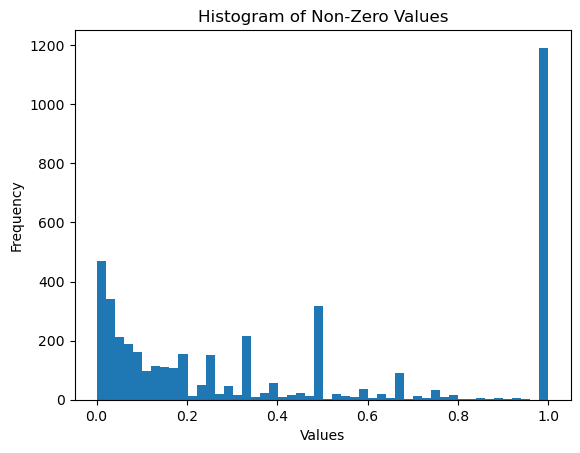

In [133]:
non_zero_values

array([0.02380952, 0.02380952, 0.02380952, ..., 1.        , 1.        ,
       1.        ])

In [119]:
import multiprocessing
distance_matrix = np.full((len(communities_E12_5), len(communities_E14_5)), -1)
subgraphs_E12_5 = []
subgraphs_E14_5 = []

def compute_distance(i, j):
    subgraph_E12_5 = G_Pinna_E12_5.subgraph(communities_E12_5[i])
    subgraph_E14_5 = G_Pinna_E14_5.subgraph(communities_E14_5[j])
    if nx.is_isomorphic(subgraph_E12_5, subgraph_E14_5):
        distance_matrix[i, j] = 0
    else:
        distance_matrix[i, j] = nx.optimize_graph_edit_distance(subgraph_E12_5, subgraph_E14_5)

pool = multiprocessing.Pool()
for i in range(len(communities_E12_5)):
    for j in range(len(communities_E14_5)):
        pool.apply_async(compute_distance, args=(i, j))

pool.close()
pool.join()


KeyboardInterrupt: 

: 

In [118]:
distance_matrix

array([[-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       ...,
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1]])

In [102]:
max(partition_Pinna_E12_5.values())

3887

In [103]:
len(community_E14_5)

3693

In [104]:
max(partition_Pinna_E14_5.values())

3691